# Task 59. Exercise on Neural Network

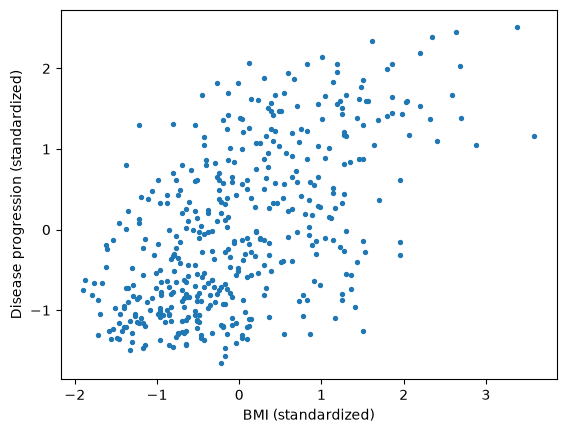

In [1]:
# ===== Loss Functions in Machine Learning =====
# Regression losses are shown with simple linear regression (Y = m*X + b)
# trained by gradient descent on one feature of the diabetes dataset.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()
X = diabetes.data[:, 2]          # BMI feature
Y = diabetes.target

# standardize both so a single learning rate works for every loss
X = (X - X.mean()) / X.std()
Y = (Y - Y.mean()) / Y.std()

plt.scatter(X, Y, s=8)
plt.xlabel('BMI (standardized)')
plt.ylabel('Disease progression (standardized)');

In [2]:
# helper that runs gradient descent with any update function and records the loss
def train(update_fn, loss_fn, X, Y, learning_rate=0.1, epochs=200):
    m, b = 0.0, 0.0
    losses = []
    for _ in range(epochs):
        m, b = update_fn(m, b, X, Y, learning_rate)
        losses.append(loss_fn(m, b, X, Y))
    return m, b, losses

In [3]:
# ===== Regression Loss 1: Mean Squared Error (MSE / L2 loss) =====
def mse_loss(m, b, X, Y):
    return np.mean((Y - (m * X + b)) ** 2)

def update_weights_MSE(m, b, X, Y, learning_rate):
    error = Y - (m * X + b)
    m_deriv = np.mean(-2 * X * error)
    b_deriv = np.mean(-2 * error)
    return m - learning_rate * m_deriv, b - learning_rate * b_deriv

m, b, mse_losses = train(update_weights_MSE, mse_loss, X, Y)
print(f"MSE:  m = {m:.4f}, b = {b:.4f}, final loss = {mse_losses[-1]:.4f}")

MSE:  m = 0.5865, b = -0.0000, final loss = 0.6561


In [4]:
# ===== Regression Loss 2: Mean Absolute Error (MAE / L1 loss) =====
def mae_loss(m, b, X, Y):
    return np.mean(np.abs(Y - (m * X + b)))

def update_weights_MAE(m, b, X, Y, learning_rate):
    error = Y - (m * X + b)
    m_deriv = np.mean(-X * np.sign(error))
    b_deriv = np.mean(-np.sign(error))
    return m - learning_rate * m_deriv, b - learning_rate * b_deriv

m, b, mae_losses = train(update_weights_MAE, mae_loss, X, Y)
print(f"MAE:  m = {m:.4f}, b = {b:.4f}, final loss = {mae_losses[-1]:.4f}")

MAE:  m = 0.6832, b = -0.0756, final loss = 0.6642


In [5]:
# ===== Regression Loss 3: Huber Loss =====
# quadratic for small errors, linear for large errors (less sensitive to outliers)
delta = 1.0

def huber_loss(m, b, X, Y):
    error = Y - (m * X + b)
    small = np.abs(error) <= delta
    return np.mean(np.where(small, 0.5 * error ** 2, delta * (np.abs(error) - 0.5 * delta)))

def update_weights_Huber(m, b, X, Y, learning_rate):
    error = Y - (m * X + b)
    grad = np.where(np.abs(error) <= delta, -error, -delta * np.sign(error))
    m_deriv = np.mean(grad * X)
    b_deriv = np.mean(grad)
    return m - learning_rate * m_deriv, b - learning_rate * b_deriv

m, b, huber_losses = train(update_weights_Huber, huber_loss, X, Y)
print(f"Huber: m = {m:.4f}, b = {b:.4f}, final loss = {huber_losses[-1]:.4f}")

Huber: m = 0.6169, b = -0.0112, final loss = 0.3066


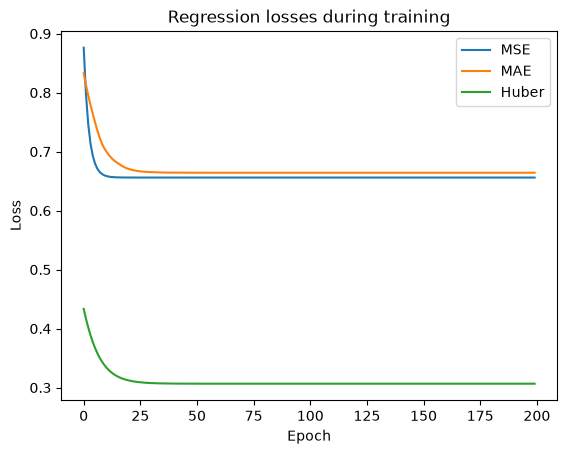

In [6]:
plt.plot(mse_losses, label='MSE')
plt.plot(mae_losses, label='MAE')
plt.plot(huber_losses, label='Huber')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Regression losses during training')
plt.legend();

In [7]:
# ===== Binary Classification Losses =====
# Breast cancer dataset, two features, gradient descent on a linear model
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()
Xb = cancer.data[:, [0, 1]]        # mean radius, mean texture
yb = cancer.target                 # 0 = malignant, 1 = benign
Xb = (Xb - Xb.mean(axis=0)) / Xb.std(axis=0)
print(Xb.shape, np.bincount(yb))

(569, 2) [212 357]


In [8]:
# ===== Binary Loss 1: Binary Cross-Entropy =====
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def bce_loss(w, b, X, y):
    p = np.clip(sigmoid(X @ w + b), 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def update_weights_BCE(w, b, X, y, learning_rate):
    p = sigmoid(X @ w + b)
    w_deriv = X.T @ (p - y) / len(y)
    b_deriv = np.mean(p - y)
    return w - learning_rate * w_deriv, b - learning_rate * b_deriv

w, b = np.zeros(2), 0.0
bce_losses = []
for _ in range(300):
    w, b = update_weights_BCE(w, b, Xb, yb, 0.1)
    bce_losses.append(bce_loss(w, b, Xb, yb))

bce_acc = np.mean((sigmoid(Xb @ w + b) > 0.5) == yb)
print("Cross-entropy accuracy:", bce_acc)

Cross-entropy accuracy: 0.8875219683655536


In [9]:
# ===== Binary Loss 2: Hinge Loss (used by SVMs) =====
# hinge loss needs labels -1 and +1
yb_pm = np.where(yb == 1, 1, -1)

def hinge_loss(w, b, X, y):
    return np.mean(np.maximum(0, 1 - y * (X @ w + b)))

def update_weights_Hinge(w, b, X, y, learning_rate):
    margin = y * (X @ w + b)
    active = margin < 1                     # only points inside the margin contribute
    w_deriv = -(X[active].T @ y[active]) / len(y)
    b_deriv = -np.sum(y[active]) / len(y)
    return w - learning_rate * w_deriv, b - learning_rate * b_deriv

w, b = np.zeros(2), 0.0
hinge_losses = []
for _ in range(300):
    w, b = update_weights_Hinge(w, b, Xb, yb_pm, 0.1)
    hinge_losses.append(hinge_loss(w, b, Xb, yb_pm))

hinge_acc = np.mean(np.sign(Xb @ w + b) == yb_pm)
print("Hinge loss accuracy:", hinge_acc)

Hinge loss accuracy: 0.8875219683655536


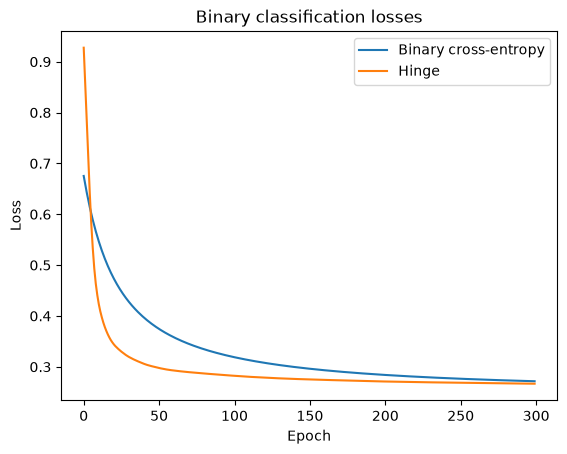

In [10]:
plt.plot(bce_losses, label='Binary cross-entropy')
plt.plot(hinge_losses, label='Hinge')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Binary classification losses')
plt.legend();

In [11]:
# ===== Multi-class Classification Losses (Keras) =====
# Iris dataset: 3 classes
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.utils import to_categorical
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.2,
                                                    random_state=42, stratify=iris.target)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

y_train_cat = to_categorical(y_train, 3)
y_test_cat = to_categorical(y_test, 3)

def build_model():
    tf.random.set_seed(42)
    return Sequential([Input(shape=(4,)), Dense(50, activation='relu'), Dense(3, activation='softmax')])

In [12]:
# ===== Multi-class Loss 1: Categorical Cross-Entropy =====
model = build_model()
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
hist_cce = model.fit(X_train, y_train_cat, epochs=100, verbose=0, validation_data=(X_test, y_test_cat))
print("Test accuracy:", model.evaluate(X_test, y_test_cat, verbose=0)[1])

Test accuracy: 0.8999999761581421


In [13]:
# ===== Multi-class Loss 2: Kullback-Leibler Divergence =====
model = build_model()
model.compile(optimizer='adam', loss='kl_divergence', metrics=['accuracy'])
hist_kl = model.fit(X_train, y_train_cat, epochs=100, verbose=0, validation_data=(X_test, y_test_cat))
print("Test accuracy:", model.evaluate(X_test, y_test_cat, verbose=0)[1])

Test accuracy: 0.8999999761581421


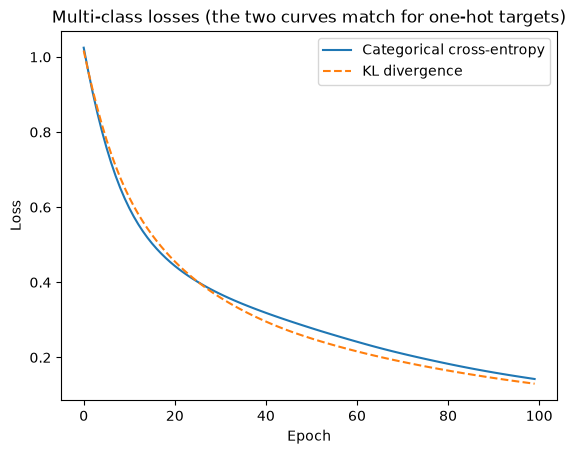

In [14]:
plt.plot(hist_cce.history['loss'], label='Categorical cross-entropy')
plt.plot(hist_kl.history['loss'], label='KL divergence', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Multi-class losses (the two curves match for one-hot targets)')
plt.legend();